# Can Partial Pooling Recover a Repeatable Receiver Effect?

The route-level dynamic Ridge and its 2023 residuals are frozen. This experiment tests whether a player's residual learned from one group of games predicts that player's average residual in held-out games. It compares three estimates: no player effect (predict zero), the raw unpooled training mean, and an empirical-Bayes mean shrunk toward zero according to a between-player variance estimate and game-cluster sampling variance.

Games are repeatedly split 100 times, balanced within week. Eligibility is fixed at 20 routes and five games in each half. Each split is evaluated in both directions. The primary outcome is held-out RMSE across eligible receivers. Split percentiles describe assignment sensitivity; paired receiver bootstraps quantify uncertainty in the RMSE differences. The plug-in effect intervals assume a normal prior and do not propagate uncertainty in the estimated prior variance.

In [1]:
from pathlib import Path
import math
import statistics
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from IPython.display import SVG, display
from separation_over_expected.receiver_effects import evaluate_partial_pooled_receiver_effects
from separation_over_expected.reports import read_csv_rows, write_csv

PREDICTIONS = PROJECT_ROOT / "data/processed/cross_season_receiver_reliability/route_predictions.csv"
OUTPUT = PROJECT_ROOT / "data/processed/receiver_effects_audit"
OUTPUT_FILES = {
    "splits": OUTPUT / "split_predictions.csv",
    "summary": OUTPUT / "metric_summary.csv",
    "effects": OUTPUT / "illustrative_receiver_effects.csv",
}
if not PREDICTIONS.exists():
    raise FileNotFoundError("Run notebook 17 or the cross-season receiver reliability command first.")
predictions = read_csv_rows(PREDICTIONS)
predictions_2023 = [row for row in predictions if row["season"] == "2023"]
len(predictions_2023), len({row["gameId"] for row in predictions_2023})

(38002, 272)

## Repeated game-held-out estimation

Training means and the empirical-Bayes prior variance use training games only. The held-out receiver outcome is that player's mean route residual minus the held-out half's league mean residual. No player ID enters the route model; player ID is used only to aggregate route residuals into the effect being tested.

In [2]:
if all(path.exists() for path in OUTPUT_FILES.values()):
    split_rows = read_csv_rows(OUTPUT_FILES["splits"])
    summary_rows = read_csv_rows(OUTPUT_FILES["summary"])
    effect_rows = read_csv_rows(OUTPUT_FILES["effects"])
else:
    split_rows, summary_rows, effect_rows = evaluate_partial_pooled_receiver_effects(
        predictions,
        split_seeds=100,
        bootstrap_samples=300,
        seed=42,
        min_routes_per_half=20,
        min_games_per_half=5,
    )
    OUTPUT.mkdir(parents=True, exist_ok=True)
    write_csv(OUTPUT_FILES["splits"], list(split_rows[0]), split_rows)
    summary_columns = list(dict.fromkeys(key for row in summary_rows for key in row))
    write_csv(OUTPUT_FILES["summary"], summary_columns, summary_rows)
    write_csv(OUTPUT_FILES["effects"], list(effect_rows[0]), effect_rows)

len(split_rows), len(summary_rows), len(effect_rows)

(200, 17, 110)

In [3]:
def metric_row(model, metric):
    return next(row for row in summary_rows if row["comparison"] == model and row["metric"] == metric)

table = []
for model, label in (
    ("no_player_effect", "No player effect"),
    ("unpooled_mean", "Unpooled mean"),
    ("partial_pool", "Partial pooled"),
):
    rmse = metric_row(model, "rmse")
    spearman = metric_row(model, "spearman")
    pearson = metric_row(model, "pearson")
    table.append({
        "estimate": label,
        "held-out RMSE (P10–P90 splits)": f'{float(rmse["median"]):.3f} '
                                           f'({float(rmse["p10"]):.3f}–{float(rmse["p90"]):.3f})',
        "held-out Pearson": f'{float(pearson["median"]):.3f}',
        "held-out Spearman": f'{float(spearman["median"]):.3f}',
    })

delta_rows = [row for row in summary_rows if row["metric"] == "rmse_delta_partial_minus_baseline"]
for row in delta_rows:
    table.append({
        "estimate": row["comparison"],
        "held-out RMSE change (95% bootstrap)": f'{float(row["median"]):+.3f} '
                                                   f'[{float(row["bootstrap_ci_lower"]):+.3f}, '
                                                   f'{float(row["bootstrap_ci_upper"]):+.3f}]',
    })
display(table)

[{'estimate': 'No player effect',
  'held-out RMSE (P10–P90 splits)': '0.277 (0.255–0.304)',
  'held-out Pearson': '0.000',
  'held-out Spearman': '0.000'},
 {'estimate': 'Unpooled mean',
  'held-out RMSE (P10–P90 splits)': '0.335 (0.302–0.379)',
  'held-out Pearson': '0.274',
  'held-out Spearman': '0.272'},
 {'estimate': 'Partial pooled',
  'held-out RMSE (P10–P90 splits)': '0.270 (0.248–0.302)',
  'held-out Pearson': '0.278',
  'held-out Spearman': '0.247'},
 {'estimate': 'partial_minus_no_player_effect',
  'held-out RMSE change (95% bootstrap)': '-0.007 [-0.031, +0.025]'},
 {'estimate': 'partial_minus_unpooled_mean',
  'held-out RMSE change (95% bootstrap)': '-0.065 [-0.130, -0.009]'}]

## Does shrinkage improve held-out receiver prediction?

Negative RMSE change favors partial pooling. The decision criterion is whether partial pooling predicts held-out receiver residual means better than both the zero-effect and unpooled baselines, with paired bootstrap intervals that support the improvement. A higher split-half correlation alone is not sufficient because shrinkage can alter the spread of estimates without improving held-out prediction.

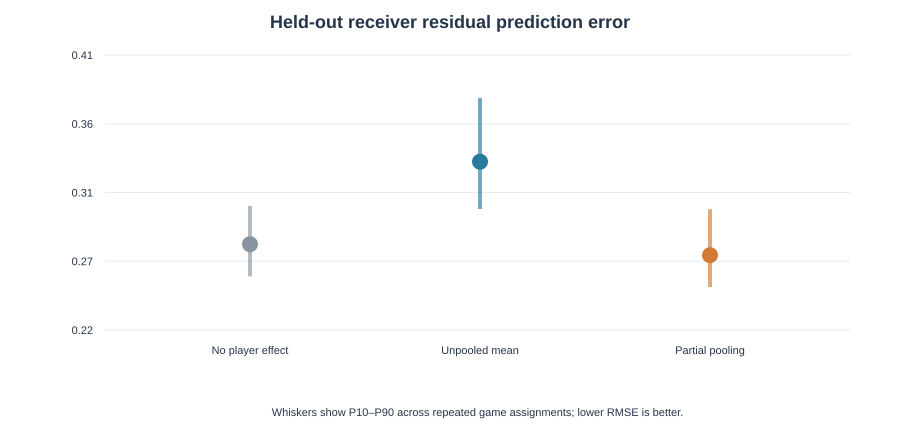

In [4]:
def prediction_plot(summary_rows, width=900, height=430):
    models = ["no_player_effect", "unpooled_mean", "partial_pool"]
    labels = ["No player effect", "Unpooled mean", "Partial pooling"]
    colors = ["#8895a1", "#287b9e", "#d17a36"]
    values = [metric_row(model, "rmse") for model in models]
    ymin = min(float(row["p10"]) for row in values) - .03
    ymax = max(float(row["p90"]) for row in values) + .03
    left, right, top, bottom = 105, 850, 55, 330
    xs = [250, 480, 710]
    y = lambda value: bottom - (float(value) - ymin) / (ymax - ymin) * (bottom - top)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}.whisker{stroke-width:4;opacity:.65}</style>',
        '<text x="450" y="28" text-anchor="middle" font-size="18" font-weight="bold">Held-out receiver residual prediction error</text>',
    ]
    for tick_index in range(5):
        value = ymin + (ymax - ymin) * tick_index / 4
        yy = y(value)
        parts.extend([
            f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
            f'<text x="{left-12}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{value:.2f}</text>',
        ])
    for x, row, label, color in zip(xs, values, labels, colors):
        median = float(row["median"])
        low, high = float(row["p10"]), float(row["p90"])
        parts.extend([
            f'<line class="whisker" x1="{x}" y1="{y(low):.1f}" x2="{x}" y2="{y(high):.1f}" stroke="{color}"/>',
            f'<circle cx="{x}" cy="{y(median):.1f}" r="8" fill="{color}"><title>median RMSE {median:.3f}; split P10–P90 {low:.3f}–{high:.3f}</title></circle>',
            f'<text x="{x}" y="{bottom+24}" text-anchor="middle" font-size="11">{label}</text>',
        ])
    parts.extend([
        f'<text x="{(left+right)/2}" y="{height-14}" text-anchor="middle" font-size="11">Whiskers show P10–P90 across repeated game assignments; lower RMSE is better.</text>',
        '</svg>',
    ])
    return "".join(parts)

display(SVG(prediction_plot(summary_rows)))

## Illustrative posterior estimates

The following fixed assignment (seed 10042, A-to-B) shows how the raw and shrunk estimates differ. Intervals are plug-in empirical-Bayes intervals; they omit uncertainty in the estimated population variance. This table is for method illustration, not a receiver leaderboard. A successful receiver effect must also predict held-out games across the repeated assignments above.

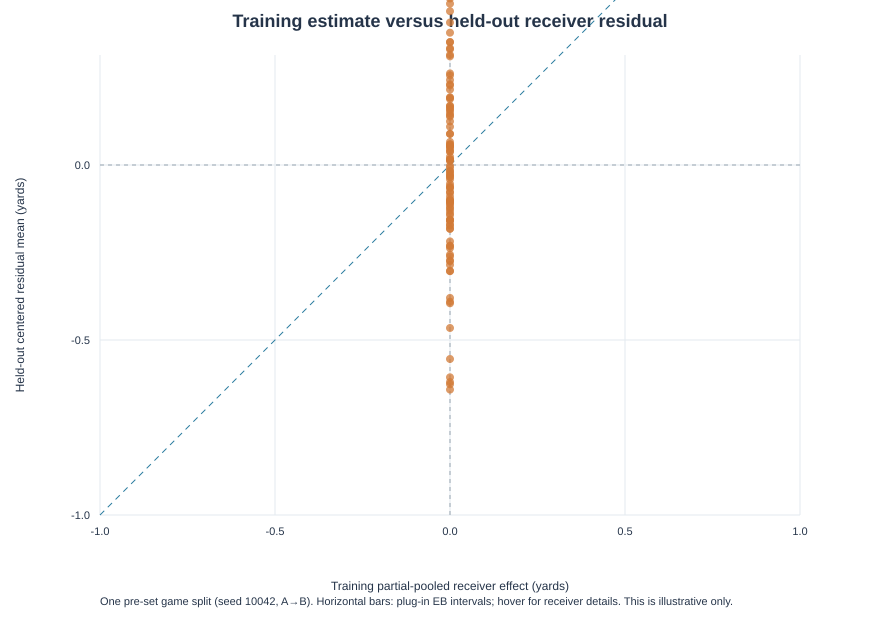

In [5]:
def effect_scatter_svg(rows, width=880, height=620):
    extent = max(
        abs(float(row[key]))
        for row in rows
        for key in ("posterior_ci_lower_plugin", "posterior_ci_upper_plugin", "heldout_centered_effect")
    )
    limit = max(.5, math.ceil(extent * 2) / 2)
    left, right, top, bottom = 100, 800, 55, 515
    scale = (right - left) / (2 * limit)
    xpos = lambda value: left + (float(value) + limit) * scale
    ypos = lambda value: bottom - (float(value) + limit) * scale
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e4e9ef}.ci{stroke:#7f8c99;stroke-width:1;opacity:.45}</style>',
        '<text x="450" y="27" text-anchor="middle" font-size="18" font-weight="bold">Training estimate versus held-out receiver residual</text>',
    ]
    for index in range(5):
        value = -limit + 2 * limit * index / 4
        xx, yy = xpos(value), ypos(value)
        parts.extend([
            f'<line class="grid" x1="{xx:.1f}" y1="{top}" x2="{xx:.1f}" y2="{bottom}"/>',
            f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
            f'<text x="{xx:.1f}" y="{bottom+20}" text-anchor="middle" font-size="11">{value:.1f}</text>',
            f'<text x="{left-10}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{value:.1f}</text>',
        ])
    parts.extend([
        f'<line x1="{xpos(-limit):.1f}" y1="{ypos(-limit):.1f}" x2="{xpos(limit):.1f}" y2="{ypos(limit):.1f}" stroke="#287b9e" stroke-dasharray="6 5"/>',
        f'<line x1="{xpos(0)}" y1="{top}" x2="{xpos(0)}" y2="{bottom}" stroke="#9aa6b2" stroke-dasharray="4 4"/>',
        f'<line x1="{left}" y1="{ypos(0)}" x2="{right}" y2="{ypos(0)}" stroke="#9aa6b2" stroke-dasharray="4 4"/>',
    ])
    for row in rows:
        x = xpos(row["training_partial_pool_effect"])
        y = ypos(row["heldout_centered_effect"])
        x1, x2 = xpos(row["posterior_ci_lower_plugin"]), xpos(row["posterior_ci_upper_plugin"])
        title = (f'{row["displayName"]}: train EB={float(row["training_partial_pool_effect"]):+.2f} yd; '
                 f'95% plug-in interval [{float(row["posterior_ci_lower_plugin"]):+.2f}, '
                 f'{float(row["posterior_ci_upper_plugin"]):+.2f}]; heldout={float(row["heldout_centered_effect"]):+.2f}')
        parts.extend([
            f'<line class="ci" x1="{x1:.1f}" y1="{y:.1f}" x2="{x2:.1f}" y2="{y:.1f}"/>',
            f'<circle cx="{x:.1f}" cy="{y:.1f}" r="4" fill="#d17a36" fill-opacity=".75"><title>{title}</title></circle>',
        ])
    parts.extend([
        f'<text x="{(left+right)/2}" y="{height-30}" text-anchor="middle" font-size="12">Training partial-pooled receiver effect (yards)</text>',
        f'<text x="24" y="{(top+bottom)/2}" text-anchor="middle" font-size="12" transform="rotate(-90 24 {(top+bottom)/2})">Held-out centered residual mean (yards)</text>',
        '<text x="100" y="605" font-size="11">One pre-set game split (seed 10042, A→B). Horizontal bars: plug-in EB intervals; hover for receiver details. This is illustrative only.</text>',
        '</svg>',
    ])
    return "".join(parts)

display(SVG(effect_scatter_svg(effect_rows)))

## Readout

Partial pooling is supported only if it improves out-of-game receiver prediction against both baselines and the paired uncertainty is favorable. If it does not, the practical conclusion is that the route residuals do not currently support a reliable individual receiver effect, even after accounting for sampling noise. That is a sharper test than asking whether a smoothed leaderboard looks stable.

In [6]:
main_result = {
    "eligible receivers per direction (median)": round(statistics.median(int(row["eligible_receivers"]) for row in split_rows)),
    "unpooled held-out RMSE": round(float(metric_row("unpooled_mean", "rmse")["median"]), 3),
    "partial-pooled held-out RMSE": round(float(metric_row("partial_pool", "rmse")["median"]), 3),
    "partial minus no-effect RMSE (95% interval)": next(
        (round(float(row["median"]), 3), round(float(row["bootstrap_ci_lower"]), 3), round(float(row["bootstrap_ci_upper"]), 3))
        for row in delta_rows if row["comparison"] == "partial_minus_no_player_effect"
    ),
    "partial minus raw-mean RMSE (95% interval)": next(
        (round(float(row["median"]), 3), round(float(row["bootstrap_ci_lower"]), 3), round(float(row["bootstrap_ci_upper"]), 3))
        for row in delta_rows if row["comparison"] == "partial_minus_unpooled_mean"
    ),
}
main_result

{'eligible receivers per direction (median)': 115,
 'unpooled held-out RMSE': 0.335,
 'partial-pooled held-out RMSE': 0.27,
 'partial minus no-effect RMSE (95% interval)': (-0.007, -0.031, 0.025),
 'partial minus raw-mean RMSE (95% interval)': (-0.065, -0.13, -0.009)}